
# Customer Cohort & Churn Analytics

## 1. Project Overview

This project analyzes customer retention and churn behavior using the IBM Telco Customer Churn dataset.

The main objective is to identify customer segments with high churn probability, analyze retention patterns across tenure cohorts, and provide data-driven recommendations to improve customer retention.

### Objectives
- Analyze customer churn behavior.
- Calculate the overall churn rate.
- Segment customers based on subscription tenure.
- Compare churn across contract types and payment methods.
- Identify high-risk customer segments.
- Visualize customer retention and churn patterns.
- Recommend strategies to reduce customer churn.

### Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly



## 2. Importing Required Libraries

Importing the Python libraries required for data manipulation, numerical analysis, statistical analysis, and visualization.


import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


## 3. Setting Up Project Directories

Creating the reports and screenshots directories to store the analysis results and visualizations.


In [9]:
Path("reports").mkdir(exist_ok=True)
Path("screenshots").mkdir(exist_ok=True)

print("Project directories created successfully!")

Project directories created successfully!



## 4. Loading the Dataset

Loading the IBM Telco Customer Churn dataset using Pandas.

The dataset contains customer information, subscription details, service usage, payment methods, monthly charges, total charges, and churn status.


In [5]:
import pandas as pd
df = pd.read_csv("data/telco_customer_churn.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



## 5. Initial Data Exploration

Inspecting the dataset structure, column names, data types, statistical summary, duplicate records, and missing values.


In [6]:
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe(include='all'))

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Duplicate Records: 0

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64



## 6. Data Cleaning and Preprocessing

The TotalCharges column is initially stored as an object data type.

Converting it into a numeric column and handling blank values.

The 11 blank TotalCharges values belong to customers with zero tenure. These values will be replaced with 0.


In [7]:
# Convert TotalCharges into numeric format

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce'
)

# Check missing values
print("Missing TotalCharges before cleaning:",
      df['TotalCharges'].isnull().sum())

# Replace missing values with zero
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Missing TotalCharges after cleaning:",
      df['TotalCharges'].isnull().sum())

print("\nUpdated Data Types:")
print(df.dtypes)

Missing TotalCharges before cleaning: 11
Missing TotalCharges after cleaning: 0

Updated Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object



## 7. Creating a Numerical Churn Indicator

Converting the categorical Churn column into numerical values.

- Yes = 1
- No = 0

This allows us to calculate churn percentages and perform numerical analysis.


In [8]:
df['Churn_Flag'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

df[['customerID', 'Churn', 'Churn_Flag']].head()

,customerID,Churn,Churn_Flag
0,7590-VHVEG,No,0
1,5575-GNVDE,No,0
2,3668-QPYBK,Yes,1
3,7795-CFOCW,No,0
4,9237-HQITU,Yes,1



# Step 2: Baseline Customer Churn Analysis

Calculating the overall customer churn rate to understand the percentage of customers who have discontinued their services.

Formula:

Churn Rate (%) = (Churned Customers / Total Customers) × 100

Retention Rate (%) = 100 - Churn Rate (%)


# Calculate customer counts

total_customers = len(df)

churned_customers = df['Churn_Flag'].sum()

retained_customers = (
    total_customers - churned_customers
)

# Calculate percentages

churn_rate = (
    churned_customers / total_customers
) * 100

retention_rate = 100 - churn_rate

# Display KPIs

print("CUSTOMER CHURN ANALYSIS")
print("-" * 40)

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)

print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")


## 8. Customer Churn Distribution Visualization

Visualizing the number of customers who have stayed with the company and those who have discontinued their services.

A count plot is used to compare the churn and non-churn customer groups.


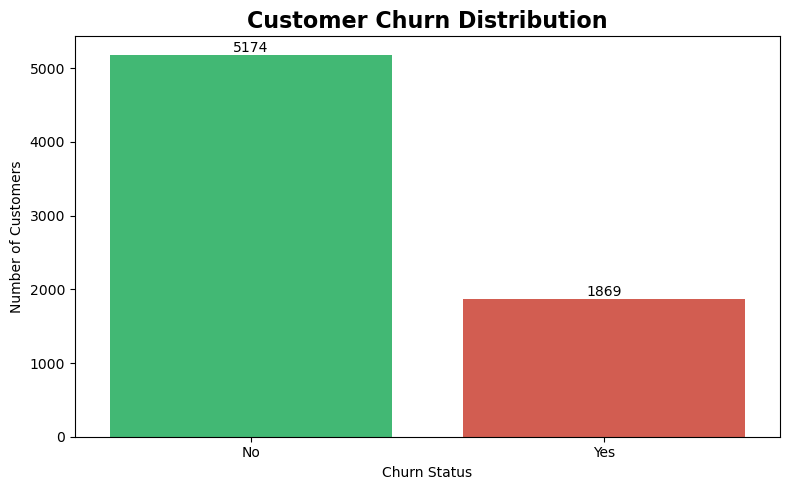

In [14]:
import os
import warnings
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Fix: suppress internal Matplotlib 3.10 float x/y deprecation
# triggered during savefig/show (not from your code)
warnings.filterwarnings(
    "ignore",
    message=".*parameter as float.*",
    category=matplotlib.MatplotlibDeprecationWarning
)

os.makedirs('screenshots', exist_ok=True)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette={
        'No': '#2ecc71',
        'Yes': '#e74c3c'
    },
    legend=False
)

plt.title(
    'Customer Churn Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

plt.savefig(
    'screenshots/churn_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()


# Step 3: Customer Cohort and Contract Analysis

Customer segmentation is performed based on subscription tenure and contract types.

Tenure cohorts help us understand how customer churn changes according to the duration of their relationship with the company.

The following tenure groups are created:

- 0–12 Months
- 13–24 Months
- 25–36 Months
- 37–48 Months
- 49–60 Months
- 61–72 Months


In [15]:
# Define tenure ranges

bins = [-1, 12, 24, 36, 48, 60, 72]

labels = [
    '0-12 Months',
    '13-24 Months',
    '25-36 Months',
    '37-48 Months',
    '49-60 Months',
    '61-72 Months'
]

# Create tenure cohort column

df['Tenure_Cohort'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels
)

# Display sample records

display(
    df[['customerID', 'tenure', 'Tenure_Cohort']].head(10)
)

,customerID,tenure,Tenure_Cohort
0,7590-VHVEG,1,0-12 Months
1,5575-GNVDE,34,25-36 Months
2,3668-QPYBK,2,0-12 Months
3,7795-CFOCW,45,37-48 Months
4,9237-HQITU,2,0-12 Months
5,9305-CDSKC,8,0-12 Months
6,1452-KIOVK,22,13-24 Months
7,6713-OKOMC,10,0-12 Months
8,7892-POOKP,28,25-36 Months
9,6388-TABGU,62,61-72 Months



## 9. Cohort Retention Analysis

Calculating the total number of customers, churned customers, churn rate, and retention rate for each tenure cohort.

The retention rate measures the proportion of customers who have not churned within each tenure group.

Formula:

Retention Rate (%) = 100 - Churn Rate (%)


In [16]:
cohort_analysis = df.groupby(
    'Tenure_Cohort',
    observed=False
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn_Flag', 'sum')
)

cohort_analysis['Churn_Rate_%'] = (
    cohort_analysis['Churned_Customers'] /
    cohort_analysis['Total_Customers']
) * 100

cohort_analysis['Retention_Rate_%'] = (
    100 - cohort_analysis['Churn_Rate_%']
)

display(cohort_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate_%,Retention_Rate_%
Tenure_Cohort,,,,
0-12 Months,2186,1037,47.44,52.56
13-24 Months,1024,294,28.71,71.29
25-36 Months,832,180,21.63,78.37
37-48 Months,762,145,19.03,80.97
49-60 Months,832,120,14.42,85.58
61-72 Months,1407,93,6.61,93.39



## 10. Customer Cohort Retention Curve

Visualizing the retention percentage across different tenure cohorts using a line chart.

This visualization helps identify how customer retention changes as subscription tenure increases.


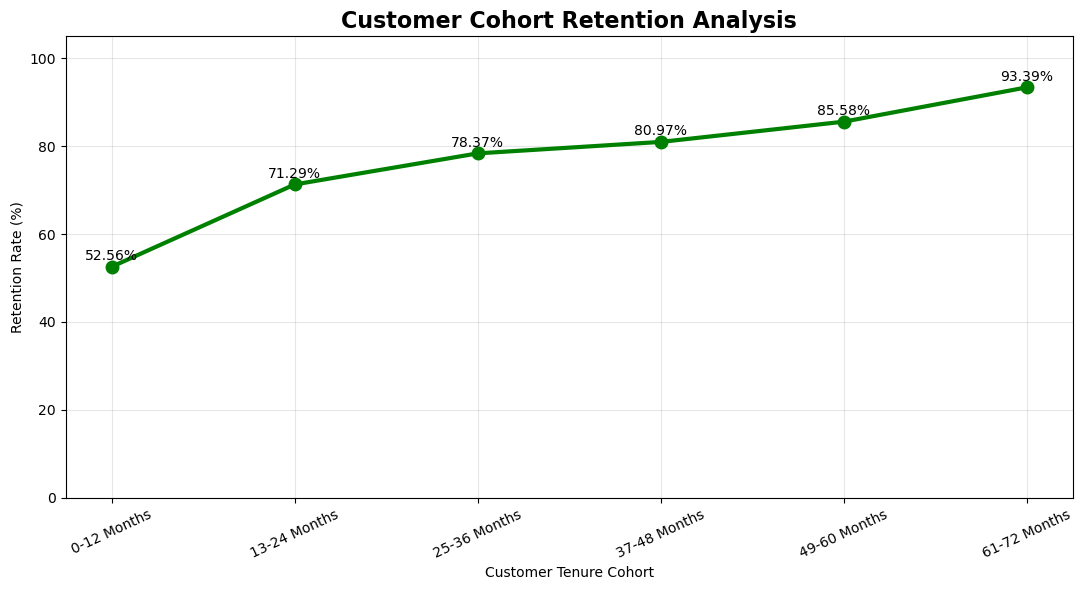

In [17]:
plt.figure(figsize=(11, 6))

plt.plot(
    cohort_analysis.index.astype(str),
    cohort_analysis['Retention_Rate_%'],
    marker='o',
    markersize=9,
    linewidth=3,
    color='green'
)

for i, value in enumerate(
    cohort_analysis['Retention_Rate_%']
):
    plt.text(
        i,
        value + 1.5,
        f'{value:.2f}%',
        ha='center',
        fontsize=10
    )

plt.title(
    'Customer Cohort Retention Analysis',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Customer Tenure Cohort')
plt.ylabel('Retention Rate (%)')

plt.ylim(0, 105)
plt.xticks(rotation=25)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'screenshots/cohort_retention.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 11. Contract-Wise Customer Churn Analysis

Analyzing customer churn based on contract types.

The dataset contains three contract categories:

- Month-to-month
- One year
- Two year

The objective is to determine which contract type has the highest customer churn rate.


In [18]:
contract_analysis = df.groupby(
    'Contract'
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn_Flag', 'sum')
)

contract_analysis['Churn_Rate_%'] = (
    contract_analysis['Churned_Customers'] /
    contract_analysis['Total_Customers']
) * 100

display(contract_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



## 12. Contract Type Churn Visualization

Creating a bar chart to compare the churn rate among month-to-month, one-year, and two-year contract customers.


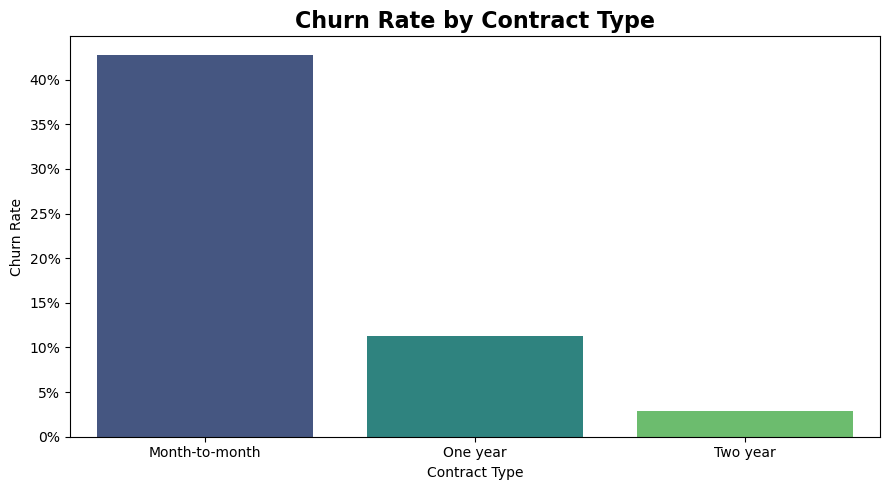

In [19]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df,
    x='Contract',
    y='Churn_Flag',
    hue='Contract',
    palette='viridis',
    estimator='mean',
    errorbar=None,
    legend=False
)

plt.title(
    'Churn Rate by Contract Type',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%')
)

plt.tight_layout()

plt.savefig(
    'screenshots/contract_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 13. Payment Method Churn Analysis

Analyzing customer churn based on payment methods.

The objective is to identify whether customers using different payment methods show different churn patterns.


In [20]:
payment_analysis = df.groupby(
    'PaymentMethod'
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn_Flag', 'sum')
)

payment_analysis['Churn_Rate_%'] = (
    payment_analysis['Churned_Customers'] /
    payment_analysis['Total_Customers']
) * 100

display(payment_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate_%
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11



## 14. Payment Method Churn Visualization

Creating a bar chart to compare the churn rate across different customer payment methods.


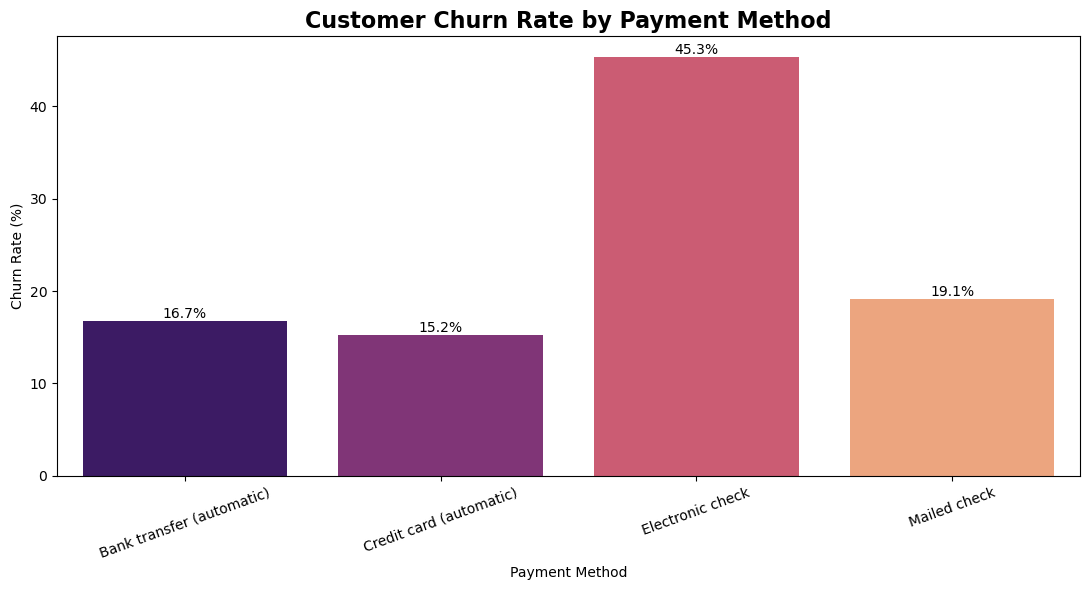

In [21]:
plt.figure(figsize=(11, 6))

payment_plot = payment_analysis.reset_index()

ax = sns.barplot(
    data=payment_plot,
    x='PaymentMethod',
    y='Churn_Rate_%',
    hue='PaymentMethod',
    palette='magma',
    legend=False
)

plt.title(
    'Customer Churn Rate by Payment Method',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.tight_layout()

plt.savefig(
    'screenshots/payment_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Step 4: High-Risk Customer Identification

Identifying customer segments with higher churn probability by analyzing internet service types, technical support availability, monthly subscription charges, and payment methods.

The objective is to identify customer groups that require targeted retention strategies.



## 15. Monthly Charges and Customer Churn Analysis

Segmenting customers into monthly charge categories to understand the relationship between subscription charges and customer churn.

The following categories are used:

- Low: Up to 35
- Medium: Above 35 to 70
- High: Above 70 to 100
- Very High: Above 100


In [23]:
import numpy as np
# Create monthly charge groups

df['Monthly_Charge_Group'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 35, 70, 100, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Analyze churn by monthly charge group

charge_analysis = df.groupby(
    'Monthly_Charge_Group',
    observed=False
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn_Flag', 'sum')
)

charge_analysis['Churn_Rate_%'] = (
    charge_analysis['Churned_Customers'] /
    charge_analysis['Total_Customers']
) * 100

display(charge_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate_%
Monthly_Charge_Group,,,
Low,1735,189,10.89
Medium,1725,413,23.94
High,2681,1014,37.82
Very High,902,253,28.05



## 16. Monthly Charges Churn Visualization

Visualizing customer churn across different monthly subscription charge categories.

A bar chart is used to identify which monthly charge category has the highest churn rate.


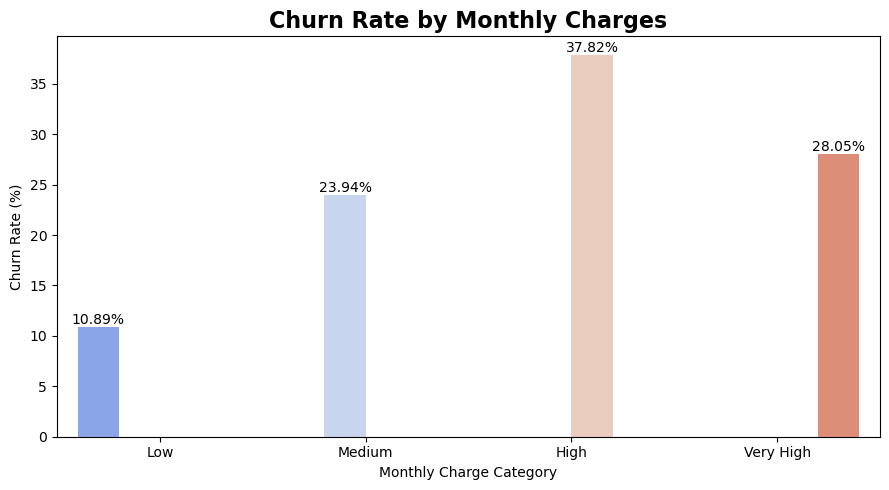

In [24]:
charge_plot = charge_analysis.reset_index()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=charge_plot,
    x='Monthly_Charge_Group',
    y='Churn_Rate_%',
    hue='Monthly_Charge_Group',
    palette='coolwarm',
    legend=False
)

plt.title(
    'Churn Rate by Monthly Charges',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Monthly Charge Category')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.tight_layout()

plt.show()


## 17. High-Risk Segment: Fiber Optic Customers Without Tech Support

Identifying customers who use Fiber Optic internet services but do not subscribe to technical support.

This segment is investigated to determine its churn rate and compare it with Fiber Optic customers who have technical support.


In [25]:
# Filter Fiber Optic customers

fiber_customers = df[
    df['InternetService'] == 'Fiber optic'
]

# Identify customers without technical support

high_risk = fiber_customers[
    fiber_customers['TechSupport'] == 'No'
]

# Calculate high-risk segment statistics

high_risk_total = len(high_risk)

high_risk_churned = high_risk['Churn_Flag'].sum()

high_risk_churn_rate = (
    high_risk_churned / high_risk_total
) * 100

print("FIBER OPTIC - WITHOUT TECH SUPPORT")
print("-" * 45)

print("Total Customers:", high_risk_total)

print("Churned Customers:", high_risk_churned)

print(
    f"Churn Rate: {high_risk_churn_rate:.2f}%"
)

FIBER OPTIC - WITHOUT TECH SUPPORT
---------------------------------------------
Total Customers: 2230
Churned Customers: 1101
Churn Rate: 49.37%



## 18. Technical Support Impact Analysis

Comparing the churn rates of Fiber Optic customers with and without technical support.

The analysis helps identify whether technical support availability is associated with improved customer retention.


In [26]:
fiber_support_analysis = fiber_customers.groupby(
    'TechSupport'
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn_Flag', 'sum')
)

fiber_support_analysis['Churn_Rate_%'] = (
    fiber_support_analysis['Churned_Customers'] /
    fiber_support_analysis['Total_Customers']
) * 100

display(fiber_support_analysis.round(2))

,Total_Customers,Churned_Customers,Churn_Rate_%
TechSupport,,,
No,2230,1101,49.37
Yes,866,196,22.63



## 19. Fiber Optic Customer Risk Visualization

Comparing customer churn rates based on technical support availability among Fiber Optic users.

The visualization highlights the difference between customers who receive technical support and those who do not.


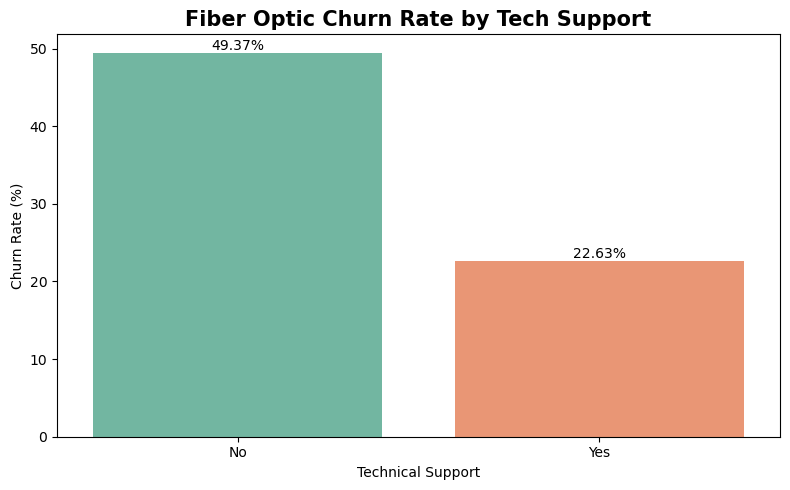

In [27]:
support_plot = fiber_support_analysis.reset_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=support_plot,
    x='TechSupport',
    y='Churn_Rate_%',
    hue='TechSupport',
    palette='Set2',
    legend=False
)

plt.title(
    'Fiber Optic Churn Rate by Tech Support',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Technical Support')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.tight_layout()

plt.savefig(
    'screenshots/fiber_tech_support_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 20. Customer Churn Heatmap

Creating a heatmap to analyze churn rates across different customer tenure cohorts and contract types.

The heatmap helps identify high-risk customer groups by comparing churn percentages across the combinations of tenure and contract categories.


Contract,Month-to-month,One year,Two year
Tenure_Cohort,,,
0-12 Months,51.35,10.48,0.00
13-24 Months,37.72,8.12,0.00
25-36 Months,32.51,8.00,2.08
37-48 Months,33.54,13.06,2.25
49-60 Months,27.78,13.71,3.97
61-72 Months,22.22,12.14,3.14


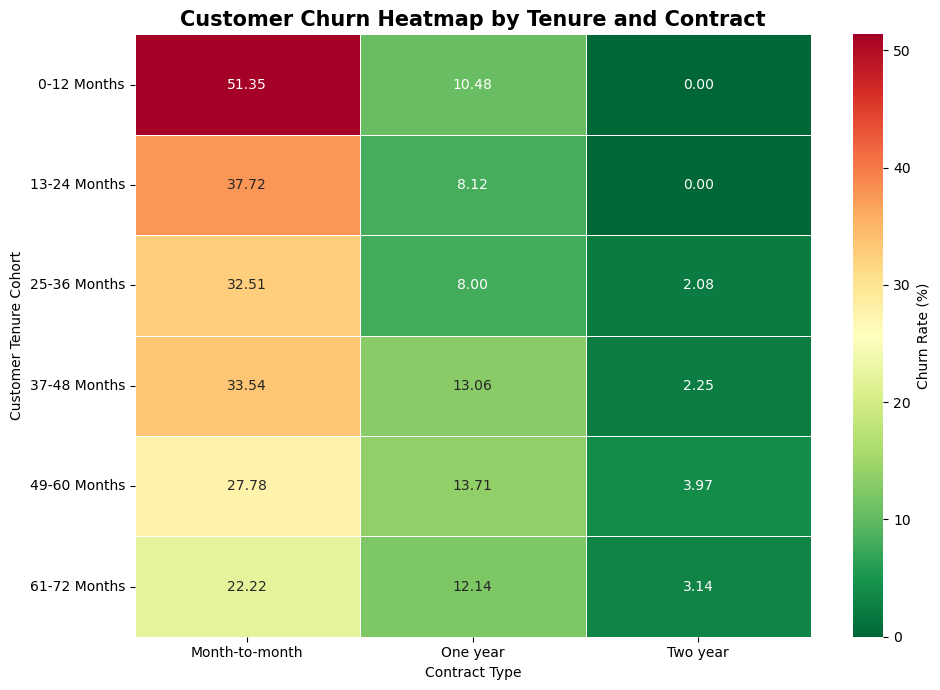

In [28]:
# Create cohort vs contract churn matrix

heatmap_data = df.pivot_table(
    index='Tenure_Cohort',
    columns='Contract',
    values='Churn_Flag',
    aggfunc='mean',
    observed=False
) * 100

# Display matrix

display(heatmap_data.round(2))

# Create heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r',
    linewidths=0.5,
    cbar_kws={
        'label': 'Churn Rate (%)'
    }
)

plt.title(
    'Customer Churn Heatmap by Tenure and Contract',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Customer Tenure Cohort')

plt.tight_layout()

plt.savefig(
    'screenshots/churn_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Step 5: Final Analysis and Business Recommendations

Summarizing the customer churn analysis results and exporting the cohort retention matrix, contract analysis, and payment method analysis.

The final deliverables include data visualizations, analytical reports, and strategic recommendations for improving customer retention.


In [29]:
cohort_analysis.to_csv(
    'reports/cohort_retention_summary.csv'
)

print("Cohort retention matrix exported successfully!")

Cohort retention matrix exported successfully!


In [30]:
contract_analysis.to_csv(
    'reports/contract_churn_summary.csv'
)

payment_analysis.to_csv(
    'reports/payment_churn_summary.csv'
)

charge_analysis.to_csv(
    'reports/monthly_charge_churn_summary.csv'
)

fiber_support_analysis.to_csv(
    'reports/fiber_tech_support_summary.csv'
)

heatmap_data.to_csv(
    'reports/cohort_contract_churn_matrix.csv'
)

print("All analysis reports exported successfully!")

All analysis reports exported successfully!



## 21. Key Business Insights

Based on the customer churn analysis, the following insights were identified:

1. Overall customer churn rate is 26.54%.
2. Month-to-month customers have a churn rate of 42.71%.
3. Two-year contract customers have a churn rate of only 2.83%.
4. Customers with 0–12 months of tenure have the lowest retention rate.
5. Electronic check users have the highest payment-method churn rate at 45.29%.
6. Customers with high monthly charges have a churn rate of 37.82%.
7. Fiber Optic customers without technical support have a churn rate of 49.37%.

These findings highlight the importance of early customer engagement, contract optimization, payment convenience, and improved technical support.



## 22. Strategic Customer Retention Recommendations

Based on the findings, the following business strategies are recommended:

### 1. Improve Early Customer Engagement
Introduce onboarding programs, welcome offers, and regular follow-ups for new customers during their first 12 months.

### 2. Encourage Long-Term Contracts
Provide discounts and loyalty benefits to encourage customers to move from month-to-month contracts to annual subscriptions.

### 3. Improve Payment Convenience
Encourage customers to use automatic payment methods and provide a simpler billing experience.

### 4. Provide Better Technical Support
Offer technical support packages and proactive troubleshooting for Fiber Optic customers.

### 5. Introduce Personalized Pricing
Provide suitable subscription plans and targeted offers to customers with higher monthly charges.

### 6. Monitor High-Risk Customers
Use churn analysis and customer segmentation to identify customers who may discontinue their services.

## 23. Conclusion

The Customer Cohort and Churn Analytics project analyzed 7,043 telecom customer records using Python.

The analysis identified an overall churn rate of 26.54% and highlighted important risk factors associated with customer churn, including short-term contracts, electronic check payments, high monthly charges, and lack of technical support.

The cohort analysis demonstrated that customer retention generally improves with subscription tenure.

The findings provide useful insights for designing targeted customer retention strategies and improving long-term business performance.

## 24. Project Outcome

Successfully completed customer churn analysis, tenure-based customer segmentation, contract analysis, payment analysis, high-risk segment identification, cohort retention visualization, and churn heatmap generation using Python.



## 25. Final Project Validation

Verifying that all analysis reports and visualization files have been generated successfully.

This final check ensures that the required project deliverables are available for submission.


In [31]:
import os

print("WEEK 3 PROJECT DELIVERABLES")
print("=" * 45)

folders = ['reports', 'screenshots']

for folder in folders:
    print(f"\n{folder.upper()}")

    for file in sorted(os.listdir(folder)):
        print("✓", file)

print("\nProject analysis completed successfully!")

WEEK 3 PROJECT DELIVERABLES

REPORTS
✓ cohort_contract_churn_matrix.csv
✓ cohort_retention_summary.csv
✓ contract_churn_summary.csv
✓ fiber_tech_support_summary.csv
✓ monthly_charge_churn_summary.csv
✓ payment_churn_summary.csv

SCREENSHOTS
✓ churn_distribution.png
✓ churn_heatmap.png
✓ cohort_retention.png
✓ contract_churn.png
✓ fiber_tech_support_churn.png
✓ payment_churn.png

Project analysis completed successfully!
